# Task 4: Customer Churn Prediction

## Project: Customer Churn Analysis and Prediction

### Objective
Build a Machine Learning model to predict whether a customer is likely to leave the company.

### Model
Logistic Regression

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix
- ROC-AUC Score

Dataset Shape: (7043, 41)

Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Training Set: (5634, 40)
Testing Set: (1409, 40)

Model Evaluation:
Accuracy: 0.7402
Precision: 0.5069
Recall: 0.7861
F1-Score: 0.6164
ROC-AUC: 0.8413

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



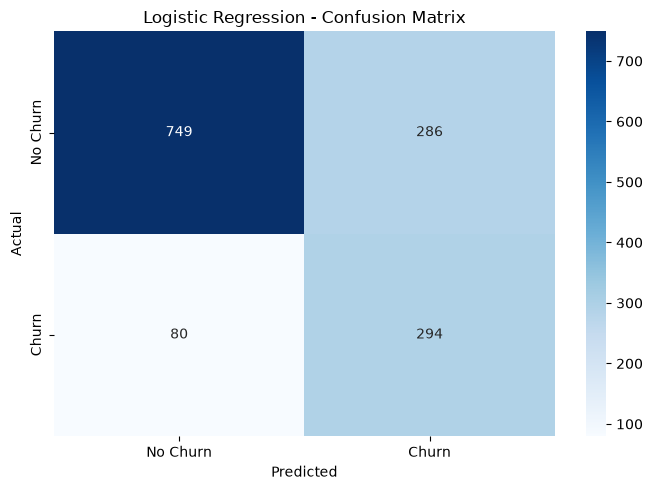

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# 1. Load encoded dataset
df = pd.read_csv(
    r"D:\Saiket_Data_Analysis\data\Telco_Customer_Churn_Encoded.csv"
)

# 2. Separate features and target
X = df.drop(columns=["Churn"])
y = df["Churn"]

print("Dataset Shape:", df.shape)
print("\nTarget Distribution:")
print(y.value_counts())

# 3. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Set:", X_train.shape)
print("Testing Set:", X_test.shape)

# 4. Build Logistic Regression Pipeline
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# 5. Train the model
model.fit(X_train, y_train)

# 6. Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# 7. Evaluate the model
print("\nModel Evaluation:")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-Score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

# 8. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig(
    r"D:\Saiket_Data_Analysis\visualizations\06_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [2]:
# Display Confusion Matrix values

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nDetailed Results:")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

Confusion Matrix:
[[749 286]
 [ 80 294]]

Detailed Results:
True Negatives: 749
False Positives: 286
False Negatives: 80
True Positives: 294


Best Threshold: 0.6308
Validation F1-Score: 0.6469

Tuned Model Evaluation:
Accuracy: 0.7715
Precision: 0.5568
Recall: 0.6818
F1-Score: 0.613
ROC-AUC: 0.8413

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.87      0.80      0.84      1035
       Churn       0.56      0.68      0.61       374

    accuracy                           0.77      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.77      0.78      1409



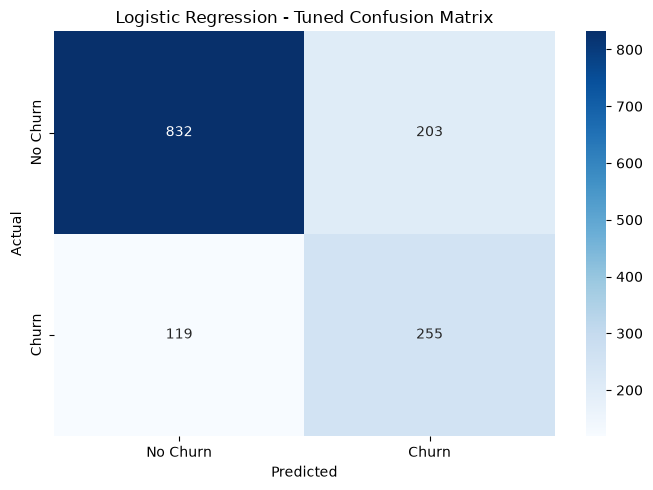

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_recall_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Split training data into training and validation sets
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# 2. Build and train a validation model
tuning_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

tuning_model.fit(X_train_new, y_train_new)

# 3. Find the best threshold using validation data
val_probabilities = tuning_model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_probabilities
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("Best Threshold:", round(best_threshold, 4))
print("Validation F1-Score:", round(f1_scores[best_index], 4))

# 4. Train the final model using all training data
tuned_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

tuned_model.fit(X_train, y_train)

# 5. Evaluate on the untouched test set
test_probabilities = tuned_model.predict_proba(X_test)[:, 1]
tuned_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("\nTuned Model Evaluation:")
print("Accuracy:", round(accuracy_score(y_test, tuned_predictions), 4))
print("Precision:", round(precision_score(y_test, tuned_predictions), 4))
print("Recall:", round(recall_score(y_test, tuned_predictions), 4))
print("F1-Score:", round(f1_score(y_test, tuned_predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probabilities), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    tuned_predictions,
    target_names=["No Churn", "Churn"]
))

# 6. Plot the new confusion matrix
tuned_cm = confusion_matrix(y_test, tuned_predictions)

plt.figure(figsize=(7, 5))
sns.heatmap(
    tuned_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Logistic Regression - Tuned Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig(
    r"D:\Saiket_Data_Analysis\visualizations\07_tuned_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

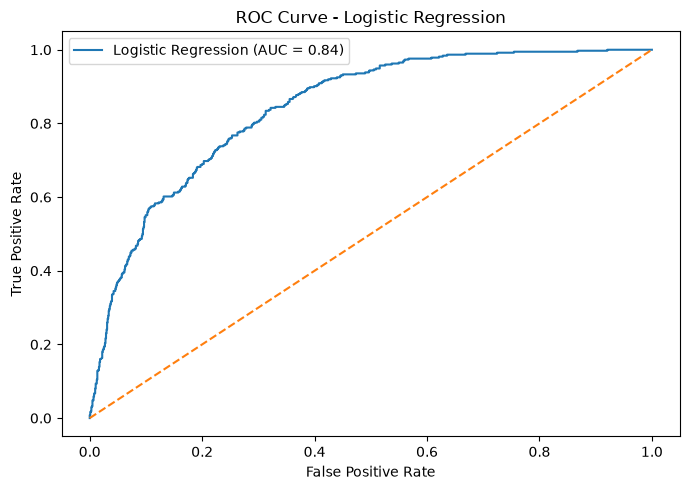

Final model and evaluation results saved successfully!

Final Metrics:
{'Model': 'Logistic Regression', 'Threshold': 0.5, 'Accuracy': 0.7402, 'Precision': 0.5069, 'Recall': 0.7861, 'F1-Score': 0.6164, 'ROC-AUC': 0.8413}


In [4]:
from pathlib import Path
import joblib
import json
import pandas as pd
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Create models folder
models_dir = Path(r"D:\Saiket_Data_Analysis\models")
models_dir.mkdir(parents=True, exist_ok=True)

# 1. Save the selected original model
joblib.dump(model, models_dir / "logistic_regression_model.pkl")

# 2. Save model evaluation metrics
final_metrics = {
    "Model": "Logistic Regression",
    "Threshold": 0.5,
    "Accuracy": round(accuracy_score(y_test, y_pred), 4),
    "Precision": round(precision_score(y_test, y_pred), 4),
    "Recall": round(recall_score(y_test, y_pred), 4),
    "F1-Score": round(f1_score(y_test, y_pred), 4),
    "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4)
}

pd.DataFrame([final_metrics]).to_csv(
    r"D:\Saiket_Data_Analysis\data\model_evaluation.csv",
    index=False
)

# 3. Save feature names
with open(models_dir / "feature_names.json", "w") as file:
    json.dump(list(X.columns), file, indent=4)

# 4. Plot ROC Curve
fpr, tpr, thresholds_roc = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve - Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()

plt.savefig(
    r"D:\Saiket_Data_Analysis\visualizations\08_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final model and evaluation results saved successfully!")
print("\nFinal Metrics:")
print(final_metrics)

## Final Model Selection and Conclusion

After evaluating the original and tuned Logistic Regression models, the original model with a 0.5 classification threshold was selected as the final model.

### Final Performance
- Accuracy: 74.02%
- Precision: 50.69%
- Recall: 78.61%
- F1-Score: 61.64%
- ROC-AUC: 84.13%

### Model Selection Reason
The original model achieved a higher Recall and F1-Score than the tuned model. Since identifying customers who are likely to leave is a key objective of churn prediction, the original model was selected.

### Conclusion
The model can identify a significant proportion of customers who are likely to churn. Combined with customer segmentation and exploratory data analysis, it provides useful insights to support customer retention strategies.

The model is an initial predictive solution and may require further optimization before production deployment.